In [12]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import random
import numpy as np
centroids =[(-5,-5),(5,5)]
cluster_std = [1,1]

X,y = make_blobs(n_samples=100,cluster_std=cluster_std, centers=centroids, n_features=2,random_state=2)

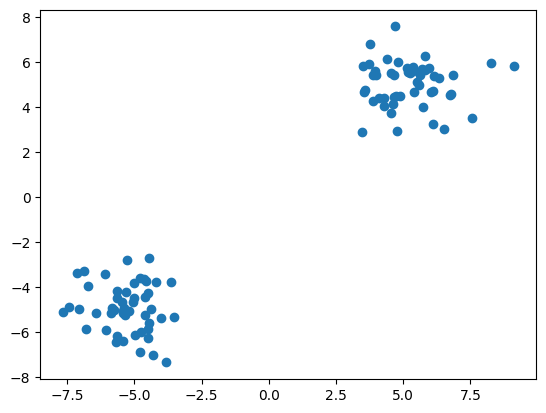

In [13]:
plt.scatter(X[:,0],X[:,1])
plt.show()

In [20]:
class Kmeans:
    def __init__(self,n_clusters=2,max_iter=100):
        self.n_clusters=n_clusters
        self.max_iter = max_iter
        self.centroids = None
    def fit_predict(self,X):

        random_index = random.sample(range(0,X.shape[0]),self.n_clusters)
        self.centroids = X[random_index]

        for i in range(self.max_iter):
            cluster_group = self.assign_clusters(X)
            old_centroids = self.centroids
            self.centroids = self.move_centroids(X,cluster_group)
            if (old_centroids == self.centroids):
                break
        return cluster_group

    def assign_clusters(self,X):
        cluster_group = []
        distances = []

        for row in X:
            for centroid in self.centroids:
                distances.append(np.sqrt(np.dot(row-centroid, row-centroid)))
            min_distance = min(distances)
            index_pos = distances.index(min_distance)
            cluster_group.append(index_pos)
            distances.clear
            
                 
        return np.array(cluster_group)
    def move_centroids(self,X,cluster_group):
        new_centroids = []

        cluster_type= np.unique(cluster_group)

        for type in cluster_type:
            new_centroids.append(X[cluster_group == type].mean(axis=0))
        return np.array(new_centroids)
        

In [21]:
km = Kmeans(n_clusters=2,max_iter=100)
y_means = km.fit_predict(X)

plt.scatter(X[y_means == 0,0],X[y_means == 0,1],colors = 'red')
plt.scatter(X[y_means == 1,0],X[y_means == 1,1],colors = 'blue')

ValueError: operands could not be broadcast together with shapes (2,2) (4,2) 